In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.colors as mplcolors
import matplotlib.ticker as ptick
import matplotlib.patches as patches
import matplotlib.patheffects as pe
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow

import time
import spiceypy as spice
import JupiterMag as jm
from CSField import CSField

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

jm.Internal.Config(Model='jrm33', Degree=3, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

csfield = CSField()
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

spice.furnsh(
    '/Users/shin/Documents/Research/Jupiter/Codes/HST/kernel/cassMetaK.txt')
radii = spice.bodvrd("JUPITER", "RADII", 3)[1]
RJ_km = radii[0]
c = radii[2]
f = (RJ_km - c) / RJ_km

Importing Library
done


In [2]:
# 定数
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492*1E+3  # Jupiter radius [m]
RE = 1560*1E+3   # Europa radius [m]
# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

Psyn_eu = (11.22)*3600      # Moon's synodic period [sec]
Psyn_ga = (10.53)*3600      # Moon's synodic period [sec]

In [3]:
def get_juno_position(et):

    # Juno position relative to Jupiter in J2000
    state, lt = spice.spkezr(
        "JUNO",
        et,
        "J2000",
        "NONE",
        "JUPITER"
    )
    r_j2000 = np.array(state[:3])

    # J2000 -> IAU_JUPITER
    rot_iau = spice.pxform(
        "J2000",
        "IAU_JUPITER",
        et
    )
    r_IAU_JUPITER = rot_iau @ r_j2000

    # Jupiter state relative to Sun in J2000
    state_jup, lt = spice.spkezr(
        "JUPITER",
        et,
        "J2000",
        "NONE",
        "SUN"
    )

    r_jup = np.array(state_jup[:3])
    v_jup = np.array(state_jup[3:6])

    # Sun direction as seen from Jupiter
    x_hat = -r_jup / np.linalg.norm(r_jup)

    # JSO Z-axis
    z_hat = np.cross(r_jup, v_jup)
    z_hat /= np.linalg.norm(z_hat)

    # JSO Y-axis
    y_hat = np.cross(z_hat, x_hat)
    y_hat /= np.linalg.norm(y_hat)

    # J2000 -> JSO
    rot_jso = np.array([
        x_hat,
        y_hat,
        z_hat
    ])

    r_jso = rot_jso @ r_j2000

    return r_jso, r_IAU_JUPITER

In [4]:
utc_start = "2016-08-01T00:00:00"
utc_end = "2016-09-10T00:00:00"

et_start = spice.str2et(utc_start)
et_end = spice.str2et(utc_end)

et = np.linspace(et_start, et_end, 10000)

pos_jso, pos_iau = np.array([
    get_juno_position(t) for t in et
]).transpose(1, 0, 2)

x_jso, y_jso, z_jso = (pos_jso / RJ_km).T
x_iau, y_iau, z_iau = (pos_iau / RJ_km).T

pos_jso = np.array([x_jso, y_jso, z_jso])
pos_iau = np.array([x_iau, y_iau, z_iau])

np.savetxt('results/Juno_trajectory/PJ01/pos_jso.txt',
           pos_jso)
np.savetxt('results/Juno_trajectory/PJ01/pos_iau.txt',
           pos_iau)

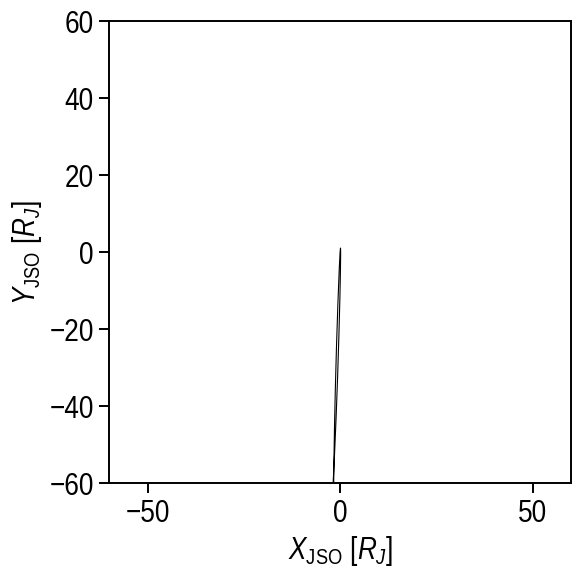

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(x_jso, y_jso, color="k", lw=0.8)

ax.set_aspect("equal")
ax.set_xlabel(r"$X_{\rm JSO}$ [$R_J$]")
ax.set_ylabel(r"$Y_{\rm JSO}$ [$R_J$]")
ax.set_xlim(-60, 60)
ax.set_ylim(-60, 60)

plt.show()

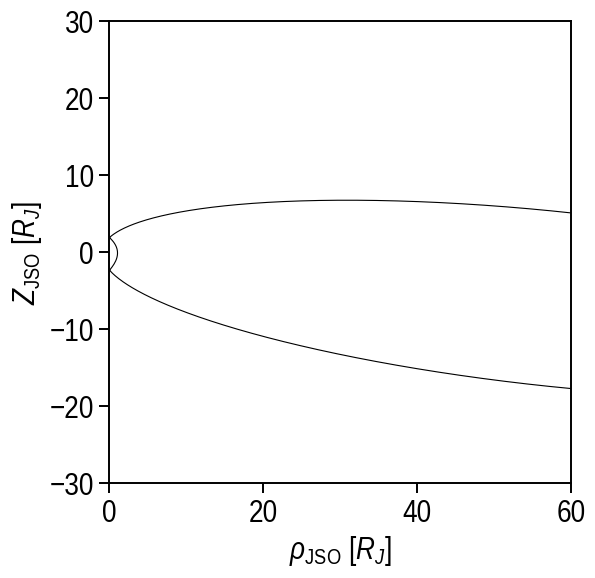

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(np.sqrt(x_jso**2+y_jso**2), z_jso, color="k", lw=0.8)

ax.set_aspect("equal")
ax.set_xlabel(r"$\rho_{\rm JSO}$ [$R_J$]")
ax.set_ylabel(r"$Z_{\rm JSO}$ [$R_J$]")
ax.set_xlim(0, 60)
ax.set_ylim(-30, 30)

plt.show()

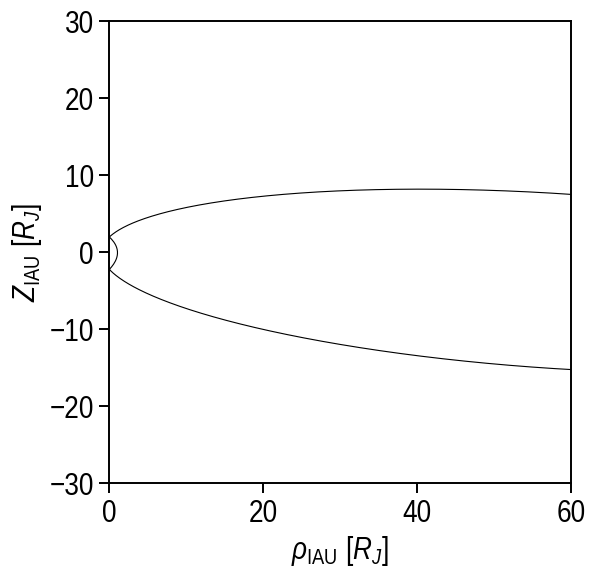

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.plot(np.sqrt(x_iau**2+y_iau**2), z_iau, color="k", lw=0.8)

ax.set_aspect("equal")
ax.set_xlabel(r"$\rho_{\rm IAU}$ [$R_J$]")
ax.set_ylabel(r"$Z_{\rm IAU}$ [$R_J$]")
ax.set_xlim(0, 60)
ax.set_ylim(-30, 30)

plt.show()

# Field line trace

In [16]:
jm.Internal.Config(Model='jrm33', Degree=1, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')
csfield.config(
    i_phi0=4.845093370096503E-5,   # 4.84800493E-5
    I_rho0=10.45591036962724,      # 8.29512904
    a0=1.87067601E-6,              # 1.85346873E-6
    MLT0=2.7409048,                # 2.55932431
    a1=25.56805279,                # 26.0564807
    MLT1=18.83227378,              # 18.851
    b1=4.2518,
    b2=0.0,
    MLTb=-0.2086,
)

In [17]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_N = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=0.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N[j, 0, k] = x_cs/RJ
            result_arr_N[j, 1, k] = y_cs/RJ
            result_arr_N[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 55.0*RJ:
            print('North edge [km]:')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_N[j, 0, k:] = np.nan
            result_arr_N[j, 1, k:] = np.nan
            result_arr_N[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

North edge [km]:
57.709430425167774 17.271845539718797
North edge [km]:
69.96866379376604 39.1755565963274
Horizontal edge
77.09206917942974 46.50137373267441
Horizontal edge
70.54966999234232 40.55944884710536
Horizontal edge
65.56298034178921 37.182253071593465
Horizontal edge
62.03615821970405 35.246366453387836
Horizontal edge
60.184914722856995 34.27898249693042
Horizontal edge
60.5465367704644 34.16875301811813
Jupiter surface
0.8993333708015636 0.07932581029330187
Jupiter surface
0.8997289214528932 0.08934821532486109
Jupiter surface
0.8991678470221002 0.10004417195849613
Jupiter surface
0.8996530725884389 0.11113687089382414
Jupiter surface
0.8998612578586394 0.12219584382256063
Jupiter surface
0.8996393472701847 0.13308424540436847
Jupiter surface
0.8987702214447162 0.14367192781115976


In [23]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE IN DUSK)
# ===========================================================
r_cs = 1.002*RJ  # [m]
theta_cs = np.radians(
    np.array([-178.0, -176.0, -174.0, -172.0, -170.0, -168.0, -166.0, -164.0]))  # Colatitude [rad]
phi_cs = 0.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

Niter = 30000

ds0 = 800000.0   # [m]
p = 1.2

result_arr_S = np.zeros((x0.size, 3, int(Niter/10)))

# 南半球から北半球へ
ns = -1     # -1: north; 1: south
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field_v2(x/RJ, y/RJ, z/RJ,
                                                  MLT=0.0)  # [T]
        # Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_S[j, 0, k] = x_cs/RJ
            result_arr_S[j, 1, k] = y_cs/RJ
            result_arr_S[j, 2, k] = z_cs/RJ
            # result_arr_S[j, 0, k] = x/RJ
            # result_arr_S[j, 1, k] = y/RJ
            # result_arr_S[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z < -55.0*RJ:
            print('South edge [km]:')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 60.0*RJ:
            print('Horizontal edge')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2+z**2) < 0.9*RJ:
            print('Jupiter surface')
            result_arr_S[j, 0, k:] = np.nan
            result_arr_S[j, 1, k:] = np.nan
            result_arr_S[j, 2, k:] = np.nan
            break

    print(rs/RJ, y/RJ)

South edge [km]:
57.7094304251666 -17.27184553971868
South edge [km]:
69.96866379376644 -39.175556596327176
Horizontal edge
77.09206917942866 -46.50137373267353
Horizontal edge
70.5496699923423 -40.559448847105315
Horizontal edge
65.562980341789 -37.182253071592584
Horizontal edge
62.03615821970464 -35.24636645338798
Horizontal edge
60.18491472285706 -34.27898249693059
Horizontal edge
60.5465367704662 -34.16875301811934


# All perijoves

In [10]:
# %% Juno's perijove times
JUNO_PJ_TIMES = [
    '2016-08-27T12:50',
    '2016-10-19T18:10',
    '2016-12-11T17:03',
    '2017-02-02T12:57',
    '2017-03-27T08:51',
    '2017-05-19T06:00',
    '2017-07-11T01:54',
    '2017-09-01T21:48',
    '2017-10-24T17:42',
    '2017-12-16T17:56',
    '2018-02-07T13:51',
    '2018-04-01T09:45',
    '2018-05-24T05:39',
    '2018-07-16T05:17',
    '2018-09-07T01:11',
    '2018-10-29T21:05',
    '2018-12-21T16:59',
    '2019-02-12T17:34',
    '2019-04-06T12:14',
    '2019-05-29T08:08',
    '2019-07-21T04:02',
    '2019-09-12T03:40',
    '2019-11-03T22:18',
    '2019-12-26T17:36',
    '2020-02-17T17:51',
    '2020-04-10T13:47',
    '2020-06-02T10:20',
    '2020-07-25T06:15',
    '2020-09-16T02:10',
    '2020-11-08T01:49',
    '2020-12-30T21:45',
    '2021-02-21T17:40',
    '2021-04-15T23:32',
    '2021-06-08T07:46',
    '2021-07-21T08:15',
    '2021-09-02T22:42',
    '2021-10-16T17:13',
    '2021-11-29T14:13',
    '2022-01-12T10:33',
    '2022-02-25T01:59',
    '2022-04-09T15:49',
    '2022-05-23T09:17',
    '2022-07-05T09:17',
    '2022-08-17T14:45',
    '2022-09-29T17:11',
    '2022-11-06T00:00',
    '2022-12-15T00:00',
    '2023-01-22T00:00',
    '2023-03-01T00:00',
    '2023-04-08T00:00',
    '2023-05-16T00:00',
    '2023-06-23T00:00',
    '2023-07-31T00:00',
    '2023-09-07T00:00',
    '2023-10-15T00:00',
    '2023-11-22T00:00',
    '2023-12-30T00:00',
    '2024-02-04T00:00',
    '2024-03-07T00:00',
    '2024-04-09T00:00',
    '2024-05-12T00:00',
    '2024-06-14T00:00',
    '2024-07-16T00:00',
    '2024-08-18T00:00',
    '2024-09-20T00:00',
    '2024-10-22T00:00',
    '2024-11-24T13:05',
    '2024-12-27T05:22',
    '2025-01-28T23:05',
    '2025-03-02T16:04',
    '2025-04-04T09:30',
    '2025-05-07T03:01',
    '2025-06-08T20:30',
    '2025-07-11T13:40',
    '2025-08-13T07:04',
    '2025-09-14T23:52',
    '2025-10-17T16:04',
    '2025-11-19T08:37',
    '2025-12-22T01:14',
    '2026-01-23T17:17',
    # '2026-02-25T09:32',
]
print(len(JUNO_PJ_TIMES))

80


In [11]:
# Sampling interval [sec]
dt = 1200.0

# Time range: +/- 5 days
duration = 26 * 24 * 3600

# Retrieve Juno trajectories
trajectory = {}

for utc in JUNO_PJ_TIMES:
    et_center = spice.str2et(utc+':00')

    et = np.arange(
        et_center - duration,
        et_center + duration + dt,
        dt
    )

    pos = np.array([
        get_juno_position(t) for t in et
    ])

    trajectory[utc] = {
        'et': et,
        'pos_jso': pos[:, 0, :],
        'pos_iau': pos[:, 1, :],
    }

# Example: first interval
et = trajectory[JUNO_PJ_TIMES[0]]['et']

pos_jso = trajectory[JUNO_PJ_TIMES[0]]['pos_jso']
pos_iau = trajectory[JUNO_PJ_TIMES[0]]['pos_iau']

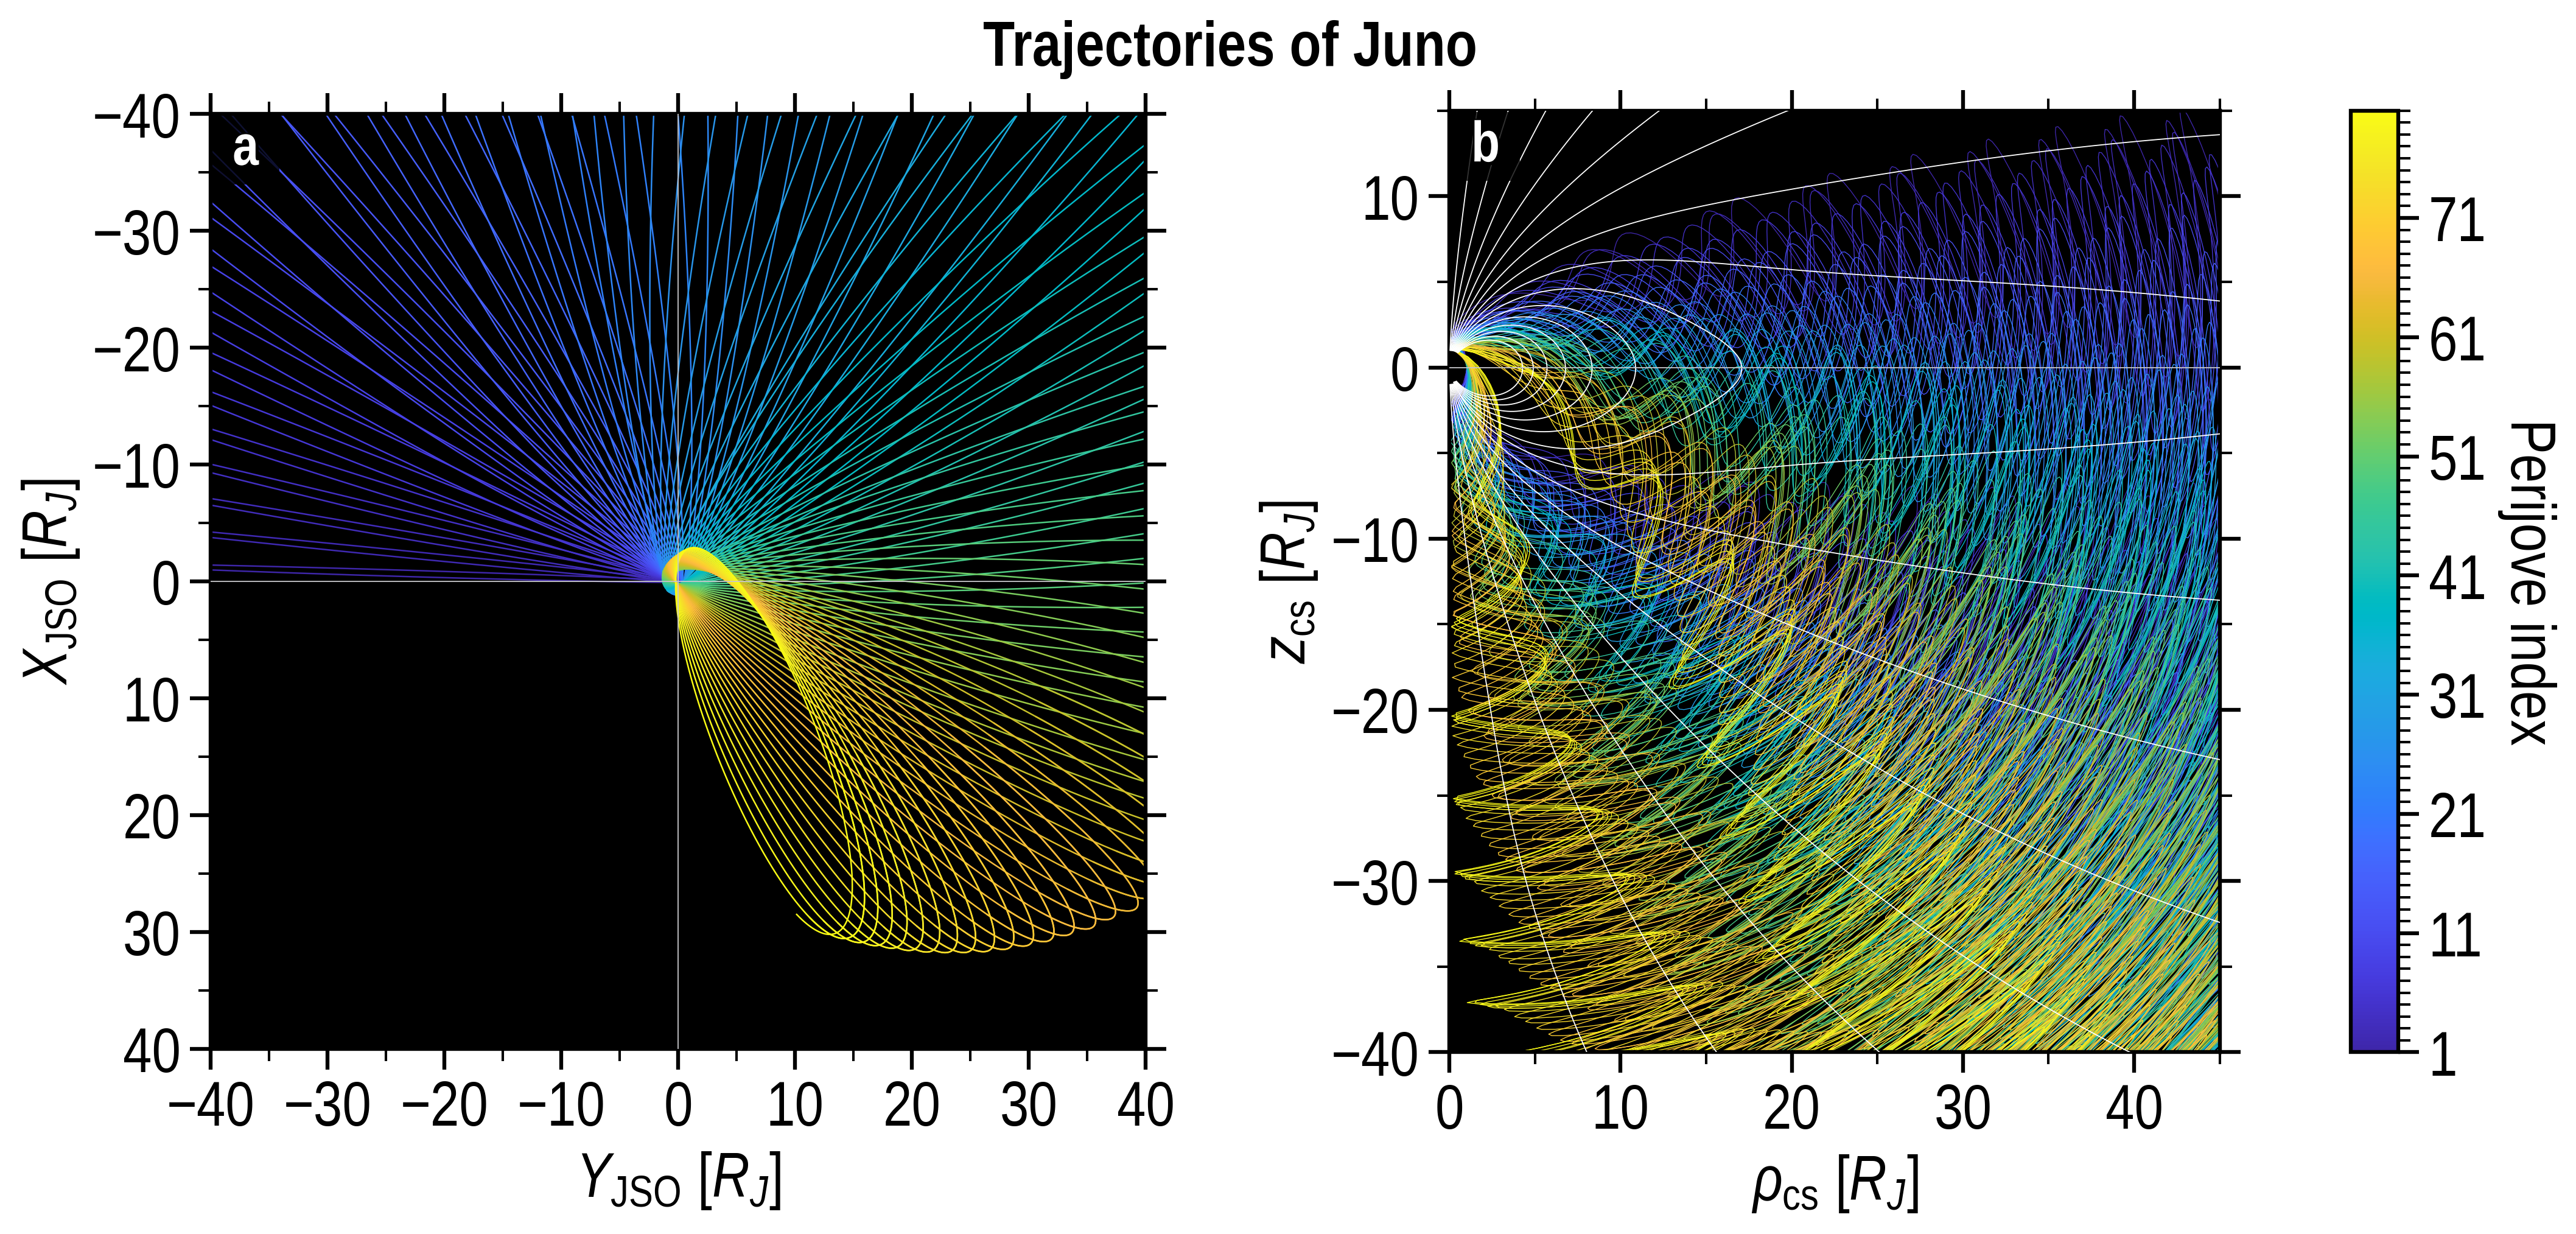

In [26]:
F.set_figparams(ncols=2, figsize=(12, 6), dpi='XL')
F.initialize()
fig, axes = F.fig, F.ax


# =====================================
# Left panel
# =====================================
ax = axes[0]
ax.set_aspect("equal")
ax.set_facecolor('k')
ax.set_xlabel(r"$Y_{\rm JSO}$ [$R_J$]")
ax.set_ylabel(r"$X_{\rm JSO}$ [$R_J$]")
ax.set_xlim(-40, 40)
ax.set_ylim(-40, 40)
ax.set_xticks(np.arange(-40, 40+1, 10, dtype=int))
ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(2))
ax.set_yticks(np.arange(-40, 40+1, 10, dtype=int))
ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(2))
ax.yaxis.set_inverted(True)
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)

vmin = 1
vmax = 80.0
cmap = F.parula()
norm = mplcolors.Normalize(vmin=vmin, vmax=vmax)

for i in range(len(JUNO_PJ_TIMES)):
    color = cmap(norm(i+1))
    lw = 0.55
    pos_jso = trajectory[JUNO_PJ_TIMES[i]]['pos_jso']
    x_jso, y_jso, z_jso = (pos_jso / RJ_km).T
    ax.plot(y_jso, x_jso, color=color, lw=lw)

# Dummy
sc = ax.scatter(-999, 999, c=1.0, vmin=1, vmax=80, cmap=cmap)

ax.axhline(y=0.0, color=UC.lightgray, linewidth=0.4, zorder=10)
ax.axvline(x=0.0, color=UC.lightgray, linewidth=0.4, zorder=10)

# Jupiter
# ax.add_patch(plt.Circle((0, 0), 1.0, color='k',
#                         zorder=11, alpha=0.5, fill=True, clip_on=True))


# =====================================
# Left panel
# =====================================
ax = axes[1]
ax.set_aspect("equal")
ax.set_facecolor('k')
ax.set_xlabel(r"$\rho_{\rm cs}$ [$R_J$]")
ax.set_ylabel(r"$z_{\rm cs}$ [$R_J$]")
ax.set_xlim(0, 45)
ax.set_ylim(-40, 15)
ax.set_xticks(np.arange(0, 45+1, 10, dtype=int))
ax.xaxis.set_minor_locator(ptick.AutoMinorLocator(2))
ax.set_yticks(np.arange(-40, 15+1, 10, dtype=int))
ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(2))
ax.tick_params(
    axis='both',       # Apply to both x and y axes
    which='both',      # Apply to both major and minor ticks
    top=True,          # Show top tick marks
    right=True,        # Show right tick marks
)

vmin = 1
vmax = 80.0
cmap = F.parula()
norm = mplcolors.Normalize(vmin=vmin, vmax=vmax)

for i in range(len(JUNO_PJ_TIMES)):
    color = cmap(norm(i+1))
    lw = 0.3
    pos_iau = trajectory[JUNO_PJ_TIMES[i]]['pos_iau']
    x_iau, y_iau, z_iau = (pos_iau / RJ_km).T

    x_cs, y_cs, z_cs = csfield._sys3_2_cs(x_iau, y_iau, z_iau)
    rho_cs = np.sqrt(x_cs**2+y_cs**2)

    ax.plot(rho_cs, z_cs, color=color, lw=lw)

ax.axhline(y=0.0, color=UC.lightgray, linewidth=0.4, zorder=10)

# Magnetic field line
for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_N[i, 2, :],
            linewidth=0.4, color='w', zorder=5)
for i in range(result_arr_S.shape[0]):
    rho_cs = np.sqrt(result_arr_S[i, 0, :]**2+result_arr_S[i, 1, :]**2)
    ax.plot(rho_cs, result_arr_S[i, 2, :],
            linewidth=0.4, color='w', zorder=5)

F.draw_panel_name(ax=axes[0], panelname=' a ')
F.draw_panel_name(ax=axes[1], panelname=' b ')

# Color bar
axpos = ax.get_position()
cax = fig.add_axes([axpos.x1*1.06, axpos.y0, 0.02, axpos.y1-axpos.y0])
pp = fig.colorbar(sc, cax=cax)
pp.ax.set_yticks(np.arange(1, 80+1, 10))
pp.ax.yaxis.set_minor_locator(ptick.AutoMinorLocator(10))
pp.ax.set_ylabel(
    r'Perijove index',
    verticalalignment='bottom',
    rotation=270)

fig.suptitle('Trajectories of Juno', y=1.0,
             fontsize=F.fontsize, fontweight="bold")

plt.savefig('img/FAC_v2/Juno_trajectory_MLT_map.pdf',
            bbox_inches='tight')

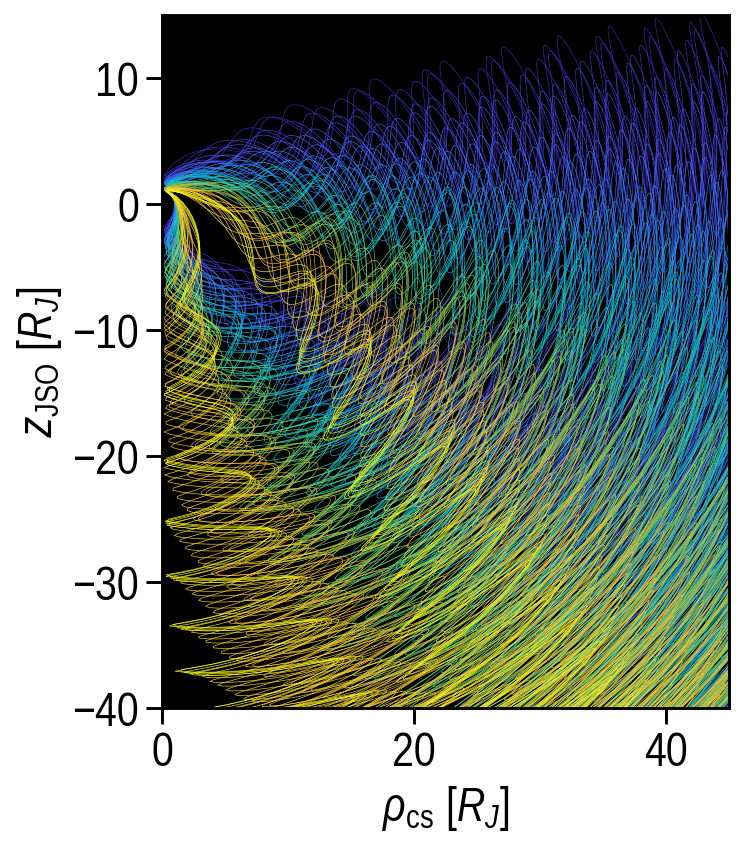

In [13]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=150)

ax.set_aspect("equal")
ax.set_facecolor('k')
ax.set_xlabel(r"$\rho_{\rm cs}$ [$R_J$]")
ax.set_ylabel(r"$z_{\rm JSO}$ [$R_J$]")
ax.set_xlim(0, 45)
ax.set_ylim(-40, 15)

vmin = 1
vmax = 80.0
cmap = F.parula()
norm = mplcolors.Normalize(vmin=vmin, vmax=vmax)

for i in range(len(JUNO_PJ_TIMES)):
    color = cmap(norm(i+1))
    lw = 0.3
    pos_iau = trajectory[JUNO_PJ_TIMES[i]]['pos_iau']
    x_iau, y_iau, z_iau = (pos_iau / RJ_km).T

    x_cs, y_cs, z_cs = csfield._sys3_2_cs(x_iau, y_iau, z_iau)
    rho_cs = np.sqrt(x_cs**2+y_cs**2)

    ax.plot(rho_cs, z_cs, color=color, lw=lw)